<a href="https://colab.research.google.com/github/julpontanares-byte/projects-portfolio/blob/main/LA1_Pontanares.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Loading Libraries**

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


**Loading and Displaying the Selected Coins**

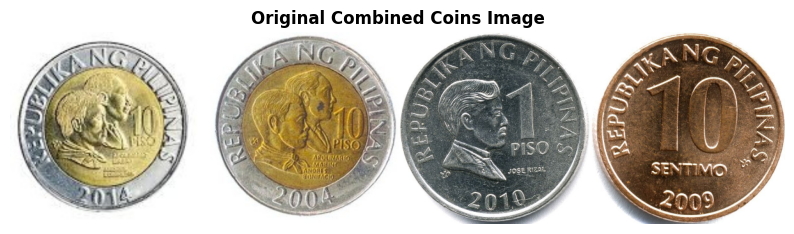

In [ ]:
# Load coins
img_10A = cv2.imread('10_pesos.jpeg')
img_10B = cv2.imread('10.2.jpeg')
img_1 = cv2.imread('1_peso.jpeg')
img_cents = cv2.imread('10_cents.jpeg')

# Resizing all images to same heights
height = 300
img_10A = cv2.resize(img_10A, (int(img_10A.shape[1] * height / img_10A.shape[0]), height))
img_10B = cv2.resize(img_10B, (int(img_10B.shape[1] * height / img_10B.shape[0]), height))
img_1 = cv2.resize(img_1, (int(img_1.shape[1] * height / img_1.shape[0]), height))
img_cents = cv2.resize(img_cents, (int(img_cents.shape[1] * height / img_cents.shape[0]), height))

# Combine image of the coins
original_combined_Pontanares = np.hstack((img_10A, img_10B, img_1, img_cents))
cv2.imwrite('LA1_Pontanares_Original.jpg', original_combined_Pontanares)

# Display Combined Original
plt.figure(figsize=(10, 4))
plt.imshow(cv2.cvtColor(original_combined_Pontanares, cv2.COLOR_BGR2RGB))
plt.title("Original Combined Coins Image", fontsize=12, fontweight='bold')
plt.axis("off")
plt.show()

**Pre-Processing**
1. Convert to Grayscale
2. Apply Noise Reduction
    *   Median Filter
    *   Gaussian Blur

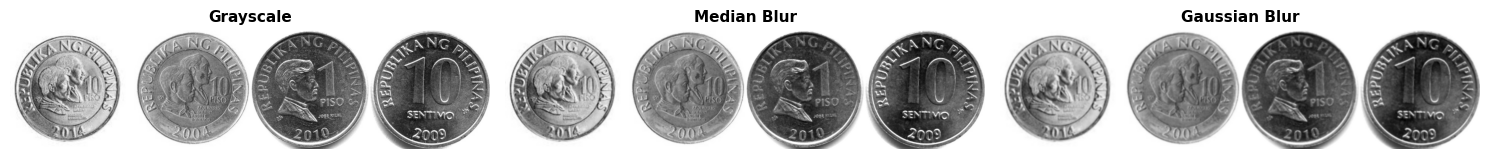

In [ ]:
# Grayscaling & Noise reduction
gray = cv2.cvtColor(original_combined_Pontanares, cv2.COLOR_BGR2GRAY)
median_blur = cv2.medianBlur(gray, 3)
gaussian_blur = cv2.GaussianBlur(median_blur, (5, 5), 0)

# Display Grayscale & Blur
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(gray, cmap='gray')
plt.title("Grayscale", fontsize=11, fontweight='bold')
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(median_blur, cmap='gray')
plt.title("Median Blur", fontsize=11, fontweight='bold')
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(gaussian_blur, cmap='gray')
plt.title("Gaussian Blur", fontsize=11, fontweight='bold')
plt.axis("off")

plt.tight_layout()
plt.show()

**Applying Convolution Operation**

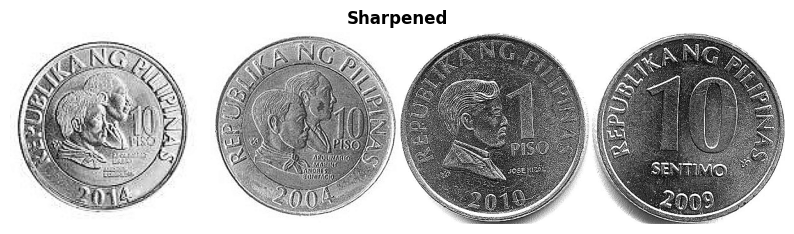

In [ ]:
# Sharpening kernel
sharpen_kernel = np.array([[0, -1, 0],
                          [-1, 5, -1],
                          [0, -1, 0]])
convolution_result = cv2.filter2D(gray, -1, sharpen_kernel)

# Display Sharpened Image
plt.figure(figsize=(10, 4))
plt.imshow(convolution_result, cmap='gray')
plt.title("Sharpened", fontsize=12, fontweight='bold')
plt.axis("off")
plt.show()

**Performing Edge Detection**

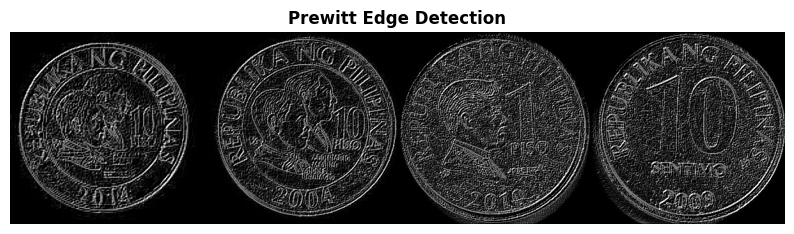

In [ ]:
# Define Prewitt kernels
kernel_x = np.array([[-1, 0, 1],
                     [-1, 0, 1],
                     [-1, 0, 1]])

kernel_y = np.array([[-1, -1, -1],
                     [ 0,  0,  0],
                     [ 1,  1,  1]])

# Apply kernels via convolution
prewitt_x = cv2.filter2D(convolution_result, -1, kernel_x)
prewitt_y = cv2.filter2D(convolution_result, -1, kernel_y)

# Combine horizontal and vertical responses
edges = cv2.addWeighted(cv2.convertScaleAbs(prewitt_x), 0.5,
                        cv2.convertScaleAbs(prewitt_y), 0.5, 0)


# Display Edge Detected Image
plt.figure(figsize=(10, 4))
plt.imshow(edges, cmap='gray')
plt.title("Prewitt Edge Detection", fontsize=12, fontweight='bold')
plt.axis("off")
plt.show()

**Cleaning the Results**

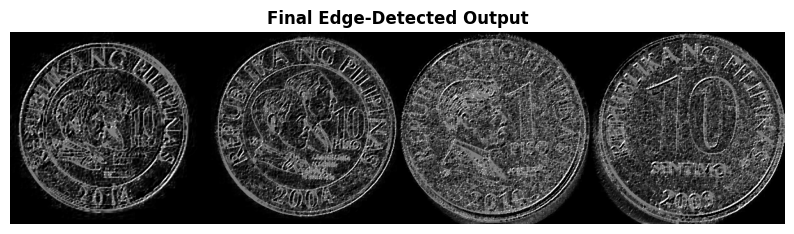

In [ ]:
kernel_morph = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
cleaned_edges = cv2.morphologyEx(edges, cv2.MORPH_CLOSE, kernel_morph)

# Save Output
cv2.imwrite('LA1_Pontanares_Edge.jpg', cleaned_edges)

# Display Final Clean Output
plt.figure(figsize=(10, 4))
plt.imshow(cleaned_edges, cmap='gray')
plt.title("Final Edge-Detected Output", fontsize=12, fontweight='bold')
plt.axis("off")
plt.show()